# 제5장 추가 실습 노트북

장 폴더에서 위에서 아래로 실행하세요. 프로그램 원본과 동일한 코드를 `%run`으로 실행합니다. 데이터 출처·가정·학습 범위는 각 절의 README를 함께 확인하세요. CSV는 내려받은 고정 입력이며 외부 API·GPU가 필요하지 않습니다.

In [1]:
import sys
from pathlib import Path
print("Python:", sys.version.split()[0])
print("Working folder:", Path.cwd())

Python: 3.12.14
Working folder: /workspace/scratch/52b332c0a516/textbook_repo/textbook_extensions/20261016/ch05


## 5.11 혼합형 데이터 전처리 Pipeline과 계수 해석

수치형과 범주형 열을 다른 절차로 바꾼 뒤 한 분류기로 연결한다.

계수의 부호는 다른 열이 고정된 선형 로그 오즈 효과다. 범주형 전체 더미와 정규화를 썼으므로 단순 인과효과나 절대 중요도로 읽지 않는다.

주의: 이탈 열과 고객 ID는 입력에서 제외했다. 총요금의 예측 시점 이용 가능성은 실제 업무에서 별도 확인해야 한다.

In [2]:
%run sec_11_mixed_pipeline.py

{
  "train_n": 840,
  "test_n": 360,
  "transformed_features": 14,
  "figure_feature_codes": {
    "F7": "cat__internet_dsl",
    "F1": "num__tenure",
    "F9": "cat__internet_none",
    "F3": "num__total_charge",
    "F11": "cat__support_yes",
    "F10": "cat__support_no",
    "F6": "cat__contract_two_year",
    "F2": "num__monthly_charge",
    "F5": "cat__contract_one_year",
    "F4": "cat__contract_monthly"
  },
  "accuracy": 0.7916666666666666,
  "f1": 0.025974025974025976
}


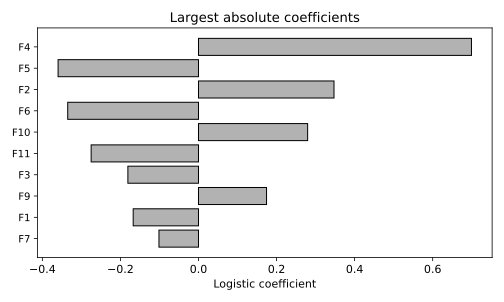

In [3]:
from IPython.display import SVG, display
display(SVG(filename="results/mixed_pipeline.svg"))

### 확인 과제

새 범주가 들어 있는 한 행을 만들어 predict가 실패하지 않는지 확인하고 출력 열 이름과 계수 수를 맞춘다.

## 5.12 훈련 통계 고정과 분포 이동 시 표준화

훈련에서 정한 평균·표준편차를 운영 입력에도 재사용하는 이유를 실험한다.

오른쪽의 현재 자료 재적합은 평균 이동을 0 근처로 지워 버린다. 두 방식은 같은 숫자 좌표를 보장하지 않는다.

주의: +25는 의도적으로 만든 가정 시나리오다. 새 모델을 평가하거나 전처리 누수의 성능 이득을 측정한 실험이 아니다.

In [4]:
%run sec_12_shift_scaler.py

{
  "training_mean": -1.6917684184764292e-17,
  "current_fixed_mean": 0.9820481867102312,
  "current_refit_mean": 8.437694987151189e-16
}


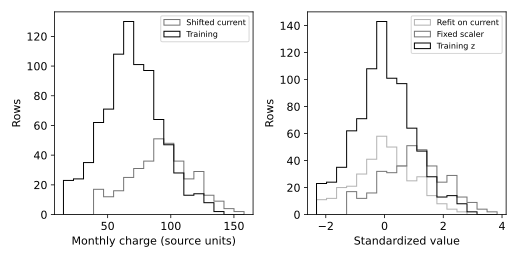

In [5]:
from IPython.display import SVG, display
display(SVG(filename="results/shift_scaler.svg"))

### 확인 과제

+25를 +0으로 바꾸고 두 변환의 차이를 다시 기록한다. 운영 전처리를 재적합하려면 모델도 함께 검증해야 함을 설명한다.